# Stage 3 – Churn Prediction, Value Weighting and Probability Calibration

Estimates a calibrated churn probability for every customer (RQ2; tests **H2** calibration and **H3** value weighting).

**Design:** 4 models (logistic regression, random forest, LightGBM, SVM) × 4 training conditions (none, class weights, value weights, SMOTE inside the folds) × 3 calibration options (raw, Platt, isotonic) = 44 combinations (the SVM has no raw probability). All choices are made with 5-fold CV on the training set; the test set is used once.

## Step 1 – Setup and data

In [1]:
# Cell 1 - Setup and data
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import StratifiedKFold, ParameterSampler, ParameterGrid
from scipy.stats import loguniform, randint

ROOT = Path.cwd()
if ROOT.name in ("src", "notebooks"):
    ROOT = ROOT.parent
sys.path.append(str(ROOT))

import config as C
from src import features as F
from src import modelling as M

train = pd.read_csv(C.PROCESSED_DIR / "train_segmented.csv")
test = pd.read_csv(C.PROCESSED_DIR / "test_segmented.csv")
SEGMENTS = ["Low-value", "New high-value", "Established high-value"]

# Model inputs: the same 18 inputs as in Stage 1 (segment labels are NOT inputs)
X_train, y_train = F.get_X_y(train.drop(columns=["segment", "segment_k4"]))
X_test, y_test = F.get_X_y(test.drop(columns=["segment", "segment_k4"]))
y_train, y_test = y_train.to_numpy(), y_test.to_numpy()

# Same chart style as the earlier notebooks
GREY = "#8a8984"
MODEL_COLOURS = {"Logistic regression": "#2a78d6", "Random forest": "#1baf7a",
                 "LightGBM": "#eda100", "SVM": "#4a3aa7"}
CAL_STYLES = {"raw": ":", "Platt": "--", "isotonic": "-"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#2b2b2b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
for d_ in (C.FIGURES_DIR, C.TABLES_DIR, C.MODELS_DIR):
    d_.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(C.FIGURES_DIR / f"{name}.png")
    print("Saved figure:", name)

def save_table(df, name):
    df.to_csv(C.TABLES_DIR / f"{name}.csv")
    print("Saved table:", name)

print(f"Train: {len(train):,} customers ({y_train.mean():.1%} churn) | "
      f"Test: {len(test):,} customers ({y_test.mean():.1%} churn) | inputs: {X_train.shape[1]}")

Train: 5,625 customers (26.6% churn) | Test: 1,407 customers (26.6% churn) | inputs: 18


## Step 2 – Campaign-profit parameters and theoretical thresholds
Profit if a contacted customer would churn: $\gamma(\mathit{CLV}_i - d) - f$; if they would stay: $-(d + f)$; not contacted: 0.
Parameters: $\mathit{CLV}_i = 12 \times$ MonthlyCharges, $d$ = mean training CLV / 20, $f = 1$, $\gamma = 0.30$.
Contacting pays off when $p_i > (d+f) / [\gamma(\mathit{CLV}_i - d) + d]$, so the threshold falls as customer value rises.

In [2]:
# Cell 2 - Profit parameters (d is a fixed business parameter computed once from the training set)
clv_train = M.customer_value(train)
clv_test = M.customer_value(test)
D = clv_train.mean() * C.INCENTIVE_RATIO

rows = []
for seg in SEGMENTS + ["All customers"]:
    mask = np.ones(len(train), bool) if seg == "All customers" else (train["segment"] == seg).to_numpy()
    mean_clv = clv_train[mask].mean()
    benefit, cost = M.profit_terms(np.array([mean_clv]), D)
    rows.append({"segment": seg, "customers": mask.sum(), "churn rate": y_train[mask].mean(),
                 "mean CLV": mean_clv, "benefit if churner contacted": benefit[0],
                 "cost if non-churner contacted": cost[0],
                 "theoretical threshold": M.theoretical_threshold(np.array([mean_clv]), D)[0]})
profit_table = pd.DataFrame(rows).set_index("segment")
save_table(profit_table.round(3), "11_profit_parameters_by_segment")
print(f"CLV mean = {clv_train.mean():.1f} | incentive d = {D:.2f} | contact f = {C.CONTACT_COST} | gamma = {C.ACCEPTANCE_RATE}")
profit_table.round(3)

Saved table: 11_profit_parameters_by_segment
CLV mean = 780.0 | incentive d = 39.00 | contact f = 1.0 | gamma = 0.3


,customers,churn rate,mean CLV,benefit if churner contacted,cost if non-churner contacted,theoretical threshold
segment,,,,,,
Low-value,1691,0.125,316.959,82.388,40.0,0.327
New high-value,2120,0.473,902.484,258.045,40.0,0.134
Established high-value,1814,0.155,1068.473,307.842,40.0,0.115
All customers,5625,0.266,779.992,221.298,40.0,0.153


## Step 3 – Instance weights
- **class:** $n / (2 n_1)$ for churners, $n / (2 n_0)$ for non-churners
- **value:** $\gamma(\mathit{CLV}_i - d) - f$ for churners, $d + f$ for non-churners, rescaled to mean 1

Weights are computed on the training part of each fold.

In [3]:
# Cell 3 - Compare the weights on the full training set (for description only)
w_class = M.class_weights(y_train)
w_value = M.value_weights(y_train, clv_train, D)
summary = []
for name, w in [("class", w_class), ("value", w_value)]:
    for seg in SEGMENTS:
        m = (train["segment"] == seg).to_numpy()
        summary.append({"condition": name, "segment": seg,
                        "mean weight churners": w[m & (y_train == 1)].mean(),
                        "mean weight non-churners": w[m & (y_train == 0)].mean()})
weights_table = pd.DataFrame(summary).set_index(["condition", "segment"])
ratio_value = w_value[y_train == 1].mean() / w_value[y_train == 0].mean()
ratio_class = w_class[y_train == 1].mean() / w_class[y_train == 0].mean()
print(f"Churner / non-churner mean weight: class = {ratio_class:.2f}, value = {ratio_value:.2f}")
save_table(weights_table.round(3), "12_instance_weights")
weights_table.round(2)

Churner / non-churner mean weight: class = 2.76, value = 6.40
Saved table: 12_instance_weights


mean weight churners  \
condition segment                                        
class     Low-value                               1.88   
          New high-value                          1.88   
          Established high-value                  1.88   
value     Low-value                               0.96   
          New high-value                          2.77   
          Established high-value                  3.40   

                                  mean weight non-churners  
condition segment                                           
class     Low-value                                   0.68  
          New high-value                              0.68  
          Established high-value                      0.68  
value     Low-value                                   0.41  
          New high-value                              0.41  
          Established high-value                      0.41

## Step 4 – Cross-validation folds and search spaces
Five stratified folds (seed 42), the same for every model and condition. Grid search for logistic regression and the SVM, random search for random forest and LightGBM. Tuned on AUC, separately for each model and condition.

In [4]:
# Cell 4 - Folds and candidate configurations
fold_id = np.zeros(len(y_train), dtype=int)
for k, (_, va) in enumerate(StratifiedKFold(C.CV_FOLDS, shuffle=True,
                                            random_state=C.RANDOM_STATE).split(X_train, y_train)):
    fold_id[va] = k

CANDIDATES = {
    "Logistic regression": list(ParameterGrid({"C": list(np.logspace(-3, 2, 11))})),
    "SVM": list(ParameterGrid({"C": [2.0 ** e for e in (-3, -1, 1, 3, 5, 7)],
                               "gamma": [2.0 ** e for e in (-11, -9, -7, -5, -3, -1)]})),
    "Random forest": list(ParameterSampler(
        {"max_features": ["sqrt", 0.3, 0.5, 0.7], "min_samples_leaf": [1, 2, 5, 10, 20, 40],
         "max_depth": [None, 6, 10, 16]},
        n_iter=C.N_RANDOM_CONFIGS["Random forest"], random_state=C.RANDOM_STATE)),
    "LightGBM": list(ParameterSampler(
        {"learning_rate": loguniform(0.01, 0.2), "num_leaves": randint(8, 65),
         "min_child_samples": randint(10, 101), "n_estimators": randint(100, 1001)},
        n_iter=C.N_RANDOM_CONFIGS["LightGBM"], random_state=C.RANDOM_STATE)),
}
print(pd.Series(np.bincount(fold_id), name="customers per fold").to_dict(),
      "| churn rate per fold:", [round(y_train[fold_id == k].mean(), 3) for k in range(C.CV_FOLDS)])
print({m: len(c) for m, c in CANDIDATES.items()}, "configurations per model and condition")

{0: 1125, 1: 1125, 2: 1125, 3: 1125, 4: 1125} | churn rate per fold: [0.266, 0.266, 0.266, 0.266, 0.266]
{'Logistic regression': 11, 'SVM': 36, 'Random forest': 30, 'LightGBM': 40} configurations per model and condition


## Step 5 – Hyperparameter tuning (5-fold CV, AUC)
Slow step (about 15–40 minutes). Results are cached in `outputs/models/stage3_tuning.joblib`; delete the file to re-tune.

In [5]:
# Cell 5 - Tune every model under every training condition
TUNING_FILE = C.MODELS_DIR / "stage3_tuning.joblib"
if TUNING_FILE.exists():
    tuning = joblib.load(TUNING_FILE)
    print("Loaded saved tuning results:", TUNING_FILE.name)
else:
    records, t0 = [], time.time()
    for model_name in M.MODELS:
        for condition in M.CONDITIONS:
            for i, params in enumerate(CANDIDATES[model_name]):
                _, _, auc = M.cross_validate(model_name, params, condition, X_train, y_train,
                                             clv_train, D, fold_id, F.make_encoder)
                records.append({"model": model_name, "condition": condition,
                                "config": i, "params": params, "cv_auc": auc})
            print(f"{model_name:20s} {condition:6s} done ({time.time() - t0:5.0f} s)")
    tuning = pd.DataFrame(records)
    joblib.dump(tuning, TUNING_FILE)

best = (tuning.sort_values("cv_auc", ascending=False)
        .groupby(["model", "condition"], sort=False).head(1)
        .set_index(["model", "condition"]).loc[[(m, c) for m in M.MODELS for c in M.CONDITIONS]])
best_show = best.assign(params=best["params"].apply(
    lambda p: ", ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in p.items())))
save_table(best_show[["params", "cv_auc"]].round(4), "13_tuning_best_configurations")
best_show[["params", "cv_auc"]].round(4)

Loaded saved tuning results: stage3_tuning.joblib
Saved table: 13_tuning_best_configurations


params  \
model               condition                                                      
Logistic regression none                                                   C=100   
                    class                                                C=31.62   
                    value                                                   C=10   
                    SMOTE                                                C=31.62   
Random forest       none       min_samples_leaf=20, max_features=sqrt, max_de...   
                    class      min_samples_leaf=20, max_features=0.3, max_dep...   
                    value      min_samples_leaf=2, max_features=0.3, max_dept...   
                    SMOTE      min_samples_leaf=40, max_features=sqrt, max_de...   
LightGBM            none       learning_rate=0.01048, min_child_samples=18, n...   
                    class      learning_rate=0.01048, min_child_samples=18, n...   
                    value      learning_rate=0.04408, min_child_samples=56, n...   
                    SMOTE      learning_rate=0.01048, min_child_samples=18, n...   
SVM                 none                                    C=32, gamma=0.001953   
                    class                                    C=2, gamma=0.007812   
                    value                                 C=0.125, gamma=0.03125   
                    SMOTE                                   C=32, gamma=0.001953   

                               cv_auc  
model               condition          
Logistic regression none       0.8448  
                    class      0.8446  
                    value      0.8316  
                    SMOTE      0.8443  
Random forest       none       0.8489  
                    class      0.8488  
                    value      0.8406  
                    SMOTE      0.8476  
LightGBM            none       0.8489  
                    class      0.8488  
                    value      0.8407  
                    SMOTE      0.8452  
SVM                 none       0.8412  
                    class      0.8427  
                    value      0.8295  
                    SMOTE      0.8443

## Step 6 – Out-of-fold predictions and cross-fitted calibration
Out-of-fold (OOF) predictions for every training customer. The calibrator for fold *k* is fitted on the OOF predictions of the other four folds, without weights.

In [6]:
# Cell 6 - OOF scores and cross-fitted calibrated probabilities
oof = {}          # (model, condition) -> dict(score, raw, Platt, isotonic)
for model_name in M.MODELS:
    for condition in M.CONDITIONS:
        params = best.loc[(model_name, condition), "params"]
        score, raw, _ = M.cross_validate(model_name, params, condition, X_train, y_train,
                                         clv_train, D, fold_id, F.make_encoder)
        oof[(model_name, condition)] = {
            "score": score,
            "raw": None if model_name == "SVM" else raw,
            "Platt": M.cross_fit_calibration("Platt", score, y_train, fold_id),
            "isotonic": M.cross_fit_calibration("isotonic", score, y_train, fold_id),
        }
print("OOF predictions ready for", len(oof), "model x condition pairs")

OOF predictions ready for 16 model x condition pairs


## Step 7 – Cross-validation results
Metrics: AUC, PR-AUC, EMP, Brier, log loss, ECE, calibration slope/intercept, profit per customer, targeted share, MCC. Used to choose the calibration, not to report final results.

In [7]:
# Cell 7 - Metrics for all 44 combinations on the OOF predictions
def results_table(pred, y, clv):
    rows = []
    for (model_name, condition), d_ in pred.items():
        for cal in M.CALIBRATIONS:
            p = d_[cal]
            if p is None:
                continue
            rows.append({"model": model_name, "condition": condition, "calibration": cal,
                         **M.evaluate(y, p, clv, D)})
    return pd.DataFrame(rows).set_index(["model", "condition", "calibration"])

cv_results = results_table(oof, y_train, clv_train)
COLS = ["AUC", "PR-AUC", "EMP per customer", "Brier", "Log loss", "ECE", "Cal. slope",
        "Cal. intercept", "Mean predicted", "Profit per customer", "Targeted share", "MCC"]
save_table(cv_results[COLS].round(4), "14_cv_results_all_combinations")
cv_results[COLS].round(3)

Saved table: 14_cv_results_all_combinations


AUC  PR-AUC  EMP per customer  \
model               condition calibration                                    
Logistic regression none      raw          0.845   0.655            50.769   
                              Platt        0.845   0.655            50.770   
                              isotonic     0.841   0.641            50.708   
                    class     raw          0.845   0.656            50.894   
                              Platt        0.844   0.655            50.830   
                              isotonic     0.841   0.641            50.903   
                    value     raw          0.831   0.636            52.050   
                              Platt        0.831   0.635            52.026   
                              isotonic     0.829   0.622            51.833   
                    SMOTE     raw          0.844   0.658            50.672   
                              Platt        0.844   0.658            50.641   
                              isotonic     0.839   0.641            50.598   
Random forest       none      raw          0.848   0.660            51.119   
                              Platt        0.848   0.660            51.100   
                              isotonic     0.844   0.645            50.898   
                    class     raw          0.848   0.660            51.149   
                              Platt        0.848   0.659            51.141   
                              isotonic     0.844   0.643            50.962   
                    value     raw          0.840   0.647            52.134   
                              Platt        0.840   0.647            52.110   
                              isotonic     0.837   0.633            51.972   
                    SMOTE     raw          0.847   0.654            50.834   
                              Platt        0.847   0.653            50.768   
                              isotonic     0.843   0.641            50.640   
LightGBM            none      raw          0.849   0.661            51.508   
                              Platt        0.849   0.661            51.484   
                              isotonic     0.846   0.647            51.328   
                    class     raw          0.848   0.660            51.528   
                              Platt        0.848   0.660            51.516   
                              isotonic     0.846   0.649            51.338   
                    value     raw          0.840   0.647            52.092   
                              Platt        0.840   0.647            52.117   
                              isotonic     0.835   0.632            51.867   
                    SMOTE     raw          0.844   0.654            50.822   
                              Platt        0.844   0.653            50.827   
                              isotonic     0.841   0.642            50.598   
SVM                 none      Platt        0.841   0.654            50.731   
                              isotonic     0.837   0.641            50.732   
                    class     Platt        0.839   0.644            50.128   
                              isotonic     0.834   0.623            49.973   
                    value     Platt        0.828   0.618            52.066   
                              isotonic     0.825   0.601            51.843   
                    SMOTE     Platt        0.843   0.656            50.667   
                              isotonic     0.840   0.643            50.427   

                                           Brier  Log loss    ECE  Cal. slope  \
model               condition calibration                                       
Logistic regression none      raw          0.136     0.418  0.015       0.973   
                              Platt        0.136     0.418  0.013       0.999   
                              isotonic     0.137     0.421  0.007       0.950   
                    class     raw          0.165   

### Choosing the calibration method
For each model and condition, the option with the lowest cross-validated Brier score is selected.

In [8]:
# Cell 8 - Selected calibration per model and condition
chosen = (cv_results["Brier"].reset_index()
          .sort_values("Brier").groupby(["model", "condition"]).head(1)
          .set_index(["model", "condition"])["calibration"])
chosen = chosen.loc[[(m, c) for m in M.MODELS for c in M.CONDITIONS]]
# For H2 we also need the better of the two calibrators (Platt or isotonic), even where raw wins
chosen_cal = (cv_results["Brier"].reset_index().query("calibration != 'raw'")
              .sort_values("Brier").groupby(["model", "condition"]).head(1)
              .set_index(["model", "condition"])["calibration"])
sel_cv = cv_results.loc[[(m, c, chosen[(m, c)]) for m, c in chosen.index]]
print("Selected option (lowest CV Brier):", chosen.value_counts().to_dict())
save_table(sel_cv[COLS].round(4), "15_cv_selected_calibration")
sel_cv[COLS].round(3)

Selected option (lowest CV Brier): {'Platt': 9, 'isotonic': 5, 'raw': 2}
Saved table: 15_cv_selected_calibration


AUC  PR-AUC  EMP per customer  \
model               condition calibration                                    
Logistic regression none      raw          0.845   0.655            50.769   
                    class     Platt        0.844   0.655            50.830   
                    value     isotonic     0.829   0.622            51.833   
                    SMOTE     Platt        0.844   0.658            50.641   
Random forest       none      Platt        0.848   0.660            51.100   
                    class     Platt        0.848   0.659            51.141   
                    value     Platt        0.840   0.647            52.110   
                    SMOTE     Platt        0.847   0.653            50.768   
LightGBM            none      raw          0.849   0.661            51.508   
                    class     Platt        0.848   0.660            51.516   
                    value     Platt        0.840   0.647            52.117   
                    SMOTE     Platt        0.844   0.653            50.827   
SVM                 none      isotonic     0.837   0.641            50.732   
                    class     isotonic     0.834   0.623            49.973   
                    value     isotonic     0.825   0.601            51.843   
                    SMOTE     isotonic     0.840   0.643            50.427   

                                           Brier  Log loss    ECE  Cal. slope  \
model               condition calibration                                       
Logistic regression none      raw          0.136     0.418  0.015       0.973   
                    class     Platt        0.136     0.418  0.013       0.999   
                    value     isotonic     0.140     0.430  0.007       0.958   
                    SMOTE     Platt        0.136     0.418  0.011       0.999   
Random forest       none      Platt        0.134     0.413  0.007       0.998   
                    class     Platt        0.134     0.413  0.009       0.998   
                    value     Platt        0.138     0.422  0.009       0.999   
                    SMOTE     Platt        0.135     0.415  0.009       0.998   
LightGBM            none      raw          0.134     0.413  0.012       1.049   
                    class     Platt        0.134     0.413  0.009       0.999   
                    value     Platt        0.137     0.422  0.017       0.999   
                    SMOTE     Platt        0.136     0.418  0.008       0.998   
SVM                 none      isotonic     0.137     0.424  0.011       0.950   
                    class     isotonic     0.139     0.432  0.013       0.900   
                    value     isotonic     0.142     0.437  0.006       0.936   
                    SMOTE     isotonic     0.136     0.421  0.009       0.950   

                                           Cal. intercept  Mean predicted  \
model               condition calibration                                   
Logistic regression none      raw                  -0.000           0.266   
                    class     Platt                 0.000           0.266   
                    value     isotonic             -0.001           0.266   
                    SMOTE     Platt                -0.000           0.266   
Random forest       none      Platt                -0.001           0.266   
                    class     Platt                 0.000           0.266   
                    value     Platt                -0.000           0.266   
                    SMOTE     Platt                 0.000           0.266   
LightGBM            none      raw                  -0.000           0.266   
                    class     Platt                 0.000           0.266   
                    value     Platt                -0.000           0.266   
                    SMOTE     Platt                -0.000           0.266   
SVM                 none      isotonic             -0.001           0.266   
                    class 

## Step 8 – Reliability diagrams (cross-validation)
Observed churn rate vs mean predicted probability in 10 bins; points on the diagonal = well calibrated.

Saved figure: 10_reliability_cv


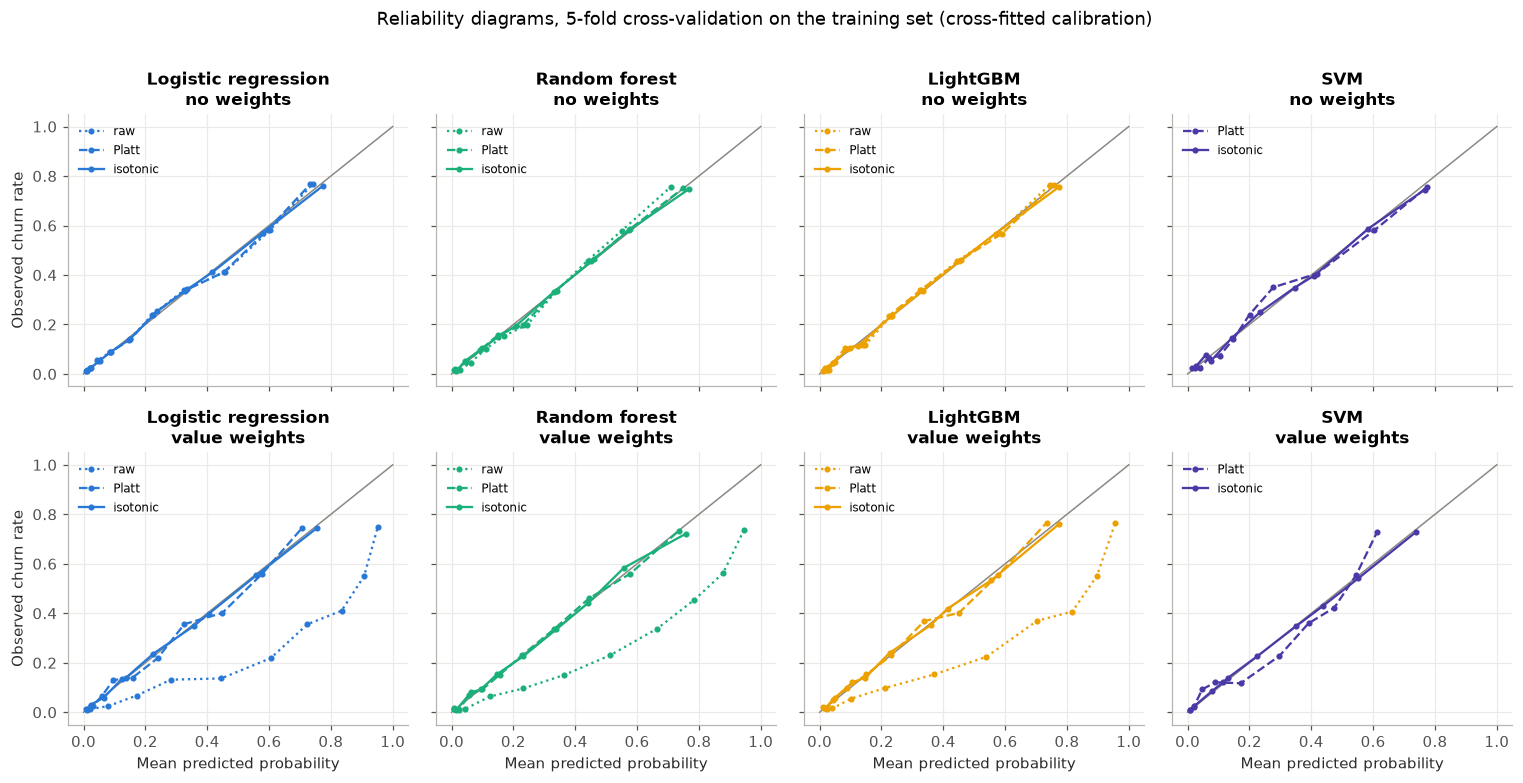

In [9]:
# Cell 9 - Reliability diagrams: no weights vs value weights, raw vs calibrated
def reliability_points(y, p, n_bins=10):
    b = pd.qcut(pd.Series(p).rank(method="first"), n_bins, labels=False)
    g = pd.DataFrame({"y": y, "p": p, "b": b}).groupby("b").mean()
    return g["p"], g["y"]

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)
for col, model_name in enumerate(M.MODELS):
    for row, condition in enumerate(["none", "value"]):
        ax = axes[row, col]
        ax.plot([0, 1], [0, 1], color=GREY, lw=1)
        for cal in M.CALIBRATIONS:
            p = oof[(model_name, condition)][cal]
            if p is None:
                continue
            x_, y_ = reliability_points(y_train, p)
            ax.plot(x_, y_, CAL_STYLES[cal], marker="o", ms=3,
                    color=MODEL_COLOURS[model_name], label=cal)
        ax.set_title(f"{model_name}\n{'no weights' if condition == 'none' else 'value weights'}")
        if row == 1:
            ax.set_xlabel("Mean predicted probability")
        if col == 0:
            ax.set_ylabel("Observed churn rate")
        ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Reliability diagrams, 5-fold cross-validation on the training set (cross-fitted calibration)", y=1.01)
fig.tight_layout()
save(fig, "10_reliability_cv")
plt.show()

## Step 9 – Final models and the single test-set evaluation
Each selected configuration is refitted on all 5,625 training customers and evaluated once on the 1,407 test customers.

In [10]:
# Cell 10 - Refit on all training data, calibrate, predict the test set
final_models, test_pred = {}, {}
for model_name in M.MODELS:
    for condition in M.CONDITIONS:
        params = best.loc[(model_name, condition), "params"]
        enc, model = M.fit_one(model_name, params, condition, X_train, y_train,
                               clv_train, D, F.make_encoder)
        score, raw = M.model_outputs(model, enc.transform(X_test))
        cals = {cal: M.fit_calibrator(cal, oof[(model_name, condition)]["score"], y_train)
                for cal in ("Platt", "isotonic")}
        final_models[(model_name, condition)] = {"encoder": enc, "model": model,
                                                 "calibrators": cals, "params": params}
        test_pred[(model_name, condition)] = {
            "score": score, "raw": raw,
            **{cal: M.apply_calibrator(c, score) for cal, c in cals.items()}}

test_results = results_table(test_pred, y_test, clv_test)
save_table(test_results[COLS].round(4), "16_test_results_all_combinations")
sel_test = test_results.loc[[(m, c, chosen[(m, c)]) for m, c in chosen.index]]
save_table(sel_test[COLS].round(4), "17_test_selected_calibration")

# Reference points: contact nobody, contact everyone, contact exactly the churners (perfect knowledge)
b_, c_ = M.profit_terms(clv_test, D)
baselines = pd.Series({
    "contact nobody": 0.0,
    "contact everyone": np.mean(y_test * b_ - (1 - y_test) * c_),
    "perfect knowledge (only churners)": np.mean(y_test * b_),
}, name="profit per customer (test)")
print(baselines.round(2).to_string())
sel_test[COLS].round(3)

Saved table: 16_test_results_all_combinations
Saved table: 17_test_selected_calibration
contact nobody                        0.00
contact everyone                     37.58
perfect knowledge (only churners)    66.95


AUC  PR-AUC  EMP per customer  \
model               condition calibration                                    
Logistic regression none      raw          0.832   0.612            48.983   
                    class     Platt        0.832   0.612            49.053   
                    value     isotonic     0.818   0.576            50.638   
                    SMOTE     Platt        0.830   0.612            48.973   
Random forest       none      Platt        0.837   0.639            49.413   
                    class     Platt        0.838   0.638            49.587   
                    value     Platt        0.826   0.616            50.058   
                    SMOTE     Platt        0.832   0.623            48.852   
LightGBM            none      raw          0.841   0.658            49.805   
                    class     Platt        0.840   0.654            49.898   
                    value     Platt        0.832   0.639            51.008   
                    SMOTE     Platt        0.836   0.634            49.061   
SVM                 none      isotonic     0.832   0.609            49.161   
                    class     isotonic     0.830   0.615            48.785   
                    value     isotonic     0.820   0.582            50.278   
                    SMOTE     isotonic     0.829   0.615            49.148   

                                           Brier  Log loss    ECE  Cal. slope  \
model               condition calibration                                       
Logistic regression none      raw          0.141     0.431  0.028       0.921   
                    class     Platt        0.142     0.431  0.025       0.946   
                    value     isotonic     0.147     0.446  0.035       0.891   
                    SMOTE     Platt        0.142     0.433  0.028       0.921   
Random forest       none      Platt        0.139     0.427  0.028       0.916   
                    class     Platt        0.139     0.426  0.025       0.932   
                    value     Platt        0.143     0.438  0.027       0.909   
                    SMOTE     Platt        0.141     0.431  0.024       0.900   
LightGBM            none      raw          0.137     0.421  0.027       1.022   
                    class     Platt        0.138     0.423  0.035       0.973   
                    value     Platt        0.142     0.431  0.032       0.963   
                    SMOTE     Platt        0.140     0.428  0.028       0.963   
SVM                 none      isotonic     0.141     0.439  0.029       0.915   
                    class     isotonic     0.142     0.435  0.039       0.985   
                    value     isotonic     0.146     0.442  0.025       0.978   
                    SMOTE     isotonic     0.141     0.431  0.021       0.956   

                                           Cal. intercept  Mean predicted  \
model               condition calibration                                   
Logistic regression none      raw                  -0.049           0.273   
                    class     Platt                -0.046           0.272   
                    value     isotonic             -0.013           0.268   
                    SMOTE     Platt                -0.033           0.270   
Random forest       none      Platt                -0.040           0.271   
                    class     Platt                -0.041           0.271   
                    value     Platt                -0.048           0.273   
                    SMOTE     Platt                -0.043           0.272   
LightGBM            none      raw                  -0.053           0.273   
                    class     Platt                -0.061           0.274   
                    value     Platt                -0.042           0.272   
                    SMOTE     Platt                -0.077           0.276   
SVM                 none      isotonic             -0.040           0.271   
                    class 

## Step 10 – Planned comparisons on the test set (H2, H3 and SMOTE)
Paired bootstrap (2,000 resamples) and DeLong test for AUC, with Holm correction.
- **H2:** best calibrator vs raw, for unweighted and value-weighted models
- **H3:** value weights vs no weights (both calibrated)
- **Reference:** SMOTE vs no weights

In [11]:
# Cell 11 - Paired bootstrap / DeLong with Holm correction
from sklearn.metrics import brier_score_loss

def profit_pc(y, p, clv):
    return M.realised_profit(y, M.contact_decision(p, clv, D), clv, D) / len(y)

def compare(label, hyp, model_name, pA, pB):
    out = []
    for metric, fn in [("Brier", brier_score_loss), ("Profit per customer", profit_pc)]:
        if metric == "Brier":
            stat = lambda i: fn(y_test[i], pA[i]) - fn(y_test[i], pB[i])
        else:
            stat = lambda i: fn(y_test[i], pA[i], clv_test[i]) - fn(y_test[i], pB[i], clv_test[i])
        obs, lo, hi, p = M.paired_bootstrap(stat, len(y_test))
        out.append({"hypothesis": hyp, "model": model_name, "comparison": label, "metric": metric,
                    "difference (A - B)": obs, "CI 2.5%": lo, "CI 97.5%": hi, "p": p})
    if hyp == "H2":      # calibration is (almost) monotone, so the AUC does not change
        return out
    diff, p = M.delong_test(y_test, pA, pB)
    out.append({"hypothesis": hyp, "model": model_name, "comparison": label, "metric": "AUC (DeLong)",
                "difference (A - B)": diff, "CI 2.5%": np.nan, "CI 97.5%": np.nan, "p": p})
    return out

rows = []
for model_name in M.MODELS:
    for condition in ["none", "value"]:
        if model_name != "SVM":
            cal = chosen_cal[(model_name, condition)]
            rows += compare(f"{condition}: {cal} vs raw", "H2", model_name,
                            test_pred[(model_name, condition)][cal],
                            test_pred[(model_name, condition)]["raw"])
    pv = test_pred[(model_name, "value")][chosen[(model_name, "value")]]
    pn = test_pred[(model_name, "none")][chosen[(model_name, "none")]]
    ps = test_pred[(model_name, "SMOTE")][chosen[(model_name, "SMOTE")]]
    rows += compare("value vs none (calibrated)", "H3", model_name, pv, pn)
    rows += compare("SMOTE vs none (calibrated)", "SMOTE", model_name, ps, pn)

comparisons = pd.DataFrame(rows)
comparisons["Holm significant"] = M.holm(comparisons["p"])
save_table(comparisons.round(4).set_index(["hypothesis", "model", "comparison", "metric"]),
           "18_test_planned_comparisons")
comparisons.round(4).set_index(["hypothesis", "model", "comparison", "metric"])

Saved table: 18_test_planned_comparisons


difference (A - B)  \
hypothesis model               comparison                 metric                                    
H2         Logistic regression none: Platt vs raw         Brier                           -0.0001   
                                                          Profit per customer             -0.1706   
                               value: isotonic vs raw     Brier                           -0.0796   
                                                          Profit per customer              0.6566   
H3         Logistic regression value vs none (calibrated) Brier                            0.0054   
                                                          Profit per customer             -1.0415   
                                                          AUC (DeLong)                    -0.0146   
SMOTE      Logistic regression SMOTE vs none (calibrated) Brier                            0.0009   
                                                          Profit per customer             -0.5376   
                                                          AUC (DeLong)                    -0.0022   
H2         Random forest       none: Platt vs raw         Brier                           -0.0000   
                                                          Profit per customer              0.8162   
                               value: Platt vs raw        Brier                           -0.0582   
                                                          Profit per customer              0.9806   
H3         Random forest       value vs none (calibrated) Brier                            0.0041   
                                                          Profit per customer             -0.7327   
                                                          AUC (DeLong)                    -0.0111   
SMOTE      Random forest       SMOTE vs none (calibrated) Brier                            0.0019   
                                                          Profit per customer             -0.3710   
                                                          AUC (DeLong)                    -0.0046   
H2         LightGBM            none: Platt vs raw         Brier                            0.0001   
                                                          Profit per customer             -0.4188   
                               value: Platt vs raw        Brier                           -0.0671   
                                                          Profit per customer              1.2491   
H3         LightGBM            value vs none (calibrated) Brier                            0.0041   
                                                          Profit per customer              0.0425   
                                                          AUC (DeLong)                    -0.0092   
SMOTE      LightGBM            SMOTE vs none (calibrated) Brier                            0.0024   
                                                          Profit per customer             -0.5182   
                                                          AUC (DeLong)                    -0.0051   
H3         SVM                 value vs none (calibrated) Brier                            0.0055   
                                                          Profit per customer             -0.4224   
                                                          AUC (DeLong)                    -0.0121   
SMOTE      SVM                 SMOTE vs none (calibrated) Brier                            0.0004   
                                                          Profit per customer              0.2452   
                                                          AUC (DeLong)                    -0.0032   

                                                                               CI 2.5%  \
hypothesis model               comparison                 metric                         
H2         Logistic regression none: Platt vs raw         Br

## Step 11 – Results by segment (test set)
Same metrics within each segment; "Mean predicted" vs "Observed rate" shows whether each segment's churn level is right.

In [12]:
# Cell 12 - Per-segment test results
rows = []
seg_test = test["segment"].to_numpy()
for model_name in M.MODELS:
    for condition in ["none", "value"]:
        cal = chosen[(model_name, condition)]
        p = test_pred[(model_name, condition)][cal]
        for seg in SEGMENTS:
            m = seg_test == seg
            r = M.evaluate(y_test[m], p[m], clv_test[m], D)
            rows.append({"model": model_name, "condition": condition, "segment": seg,
                         "customers": m.sum(), "churners": y_test[m].sum(), **r})
seg_results = pd.DataFrame(rows).set_index(["model", "condition", "segment"])
SEG_COLS = ["customers", "churners", "AUC", "Brier", "Mean predicted", "Observed rate",
            "Profit per customer", "Targeted share"]
save_table(seg_results[SEG_COLS].round(4), "19_test_results_by_segment")
seg_results[SEG_COLS].round(3)

Saved table: 19_test_results_by_segment


customers  churners  \
model               condition segment                                       
Logistic regression none      Low-value                     446        54   
                              New high-value                523       253   
                              Established high-value        438        67   
                    value     Low-value                     446        54   
                              New high-value                523       253   
                              Established high-value        438        67   
Random forest       none      Low-value                     446        54   
                              New high-value                523       253   
                              Established high-value        438        67   
                    value     Low-value                     446        54   
                              New high-value                523       253   
                              Established high-value        438        67   
LightGBM            none      Low-value                     446        54   
                              New high-value                523       253   
                              Established high-value        438        67   
                    value     Low-value                     446        54   
                              New high-value                523       253   
                              Established high-value        438        67   
SVM                 none      Low-value                     446        54   
                              New high-value                523       253   
                              Established high-value        438        67   
                    value     Low-value                     446        54   
                              New high-value                523       253   
                              Established high-value        438        67   

                                                        AUC  Brier  \
model               condition segment                                
Logistic regression none      Low-value               0.868  0.081   
                              New high-value          0.703  0.220   
                              Established high-value  0.783  0.109   
                    value     Low-value               0.847  0.087   
                              New high-value          0.690  0.225   
                              Established high-value  0.778  0.114   
Random forest       none      Low-value               0.879  0.079   
                              New high-value          0.726  0.213   
                              Established high-value  0.764  0.113   
                    value     Low-value               0.853  0.084   
                              New high-value          0.715  0.216   
                              Established high-value  0.761  0.117   
LightGBM            none      Low-value               0.877  0.079   
                              New high-value          0.729  0.211   
                              Established high-value  0.782  0.110   
                    value     Low-value               0.860  0.084   
                              New high-value          0.730  0.211   
                              Established high-value  0.773  0.117   
SVM                 none      Low-value               0.864  0.081   
                              New high-value          0.712  0.218   
                              Established high-value  0.777  0.110   
                    value     Low-value               0.846  0.088   
                              New high-value          0.703  0.220   
                              Established high-value  0.772  0.118   

                                                      Mean predicted  \
model               condition segment                                  
Logistic regression none      Low-value                        0.129   
              

Saved figure: 11_test_profit_by_condition


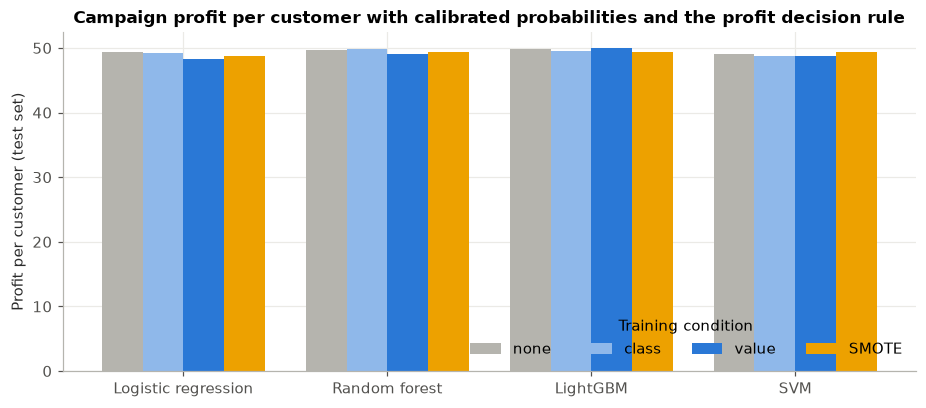

In [13]:
# Cell 13 - Figure: profit per customer on the test set, by model and condition
fig, ax = plt.subplots(figsize=(10, 4))
width = 0.2
x = np.arange(len(M.MODELS))
for j, condition in enumerate(M.CONDITIONS):
    vals = [sel_test.loc[(m, condition, chosen[(m, condition)]), "Profit per customer"] for m in M.MODELS]
    ax.bar(x + (j - 1.5) * width, vals, width, label=condition,
           color=["#b5b4ae", "#8fb8ea", "#2a78d6", "#eda100"][j])
ax.set_xticks(x, M.MODELS)
ax.set_ylabel("Profit per customer (test set)")
ax.set_title("Campaign profit per customer with calibrated probabilities and the profit decision rule")
ax.legend(title="Training condition", ncols=4, loc="lower right")
save(fig, "11_test_profit_by_condition")
plt.show()

Saved figure: 12_segment_calibration_test


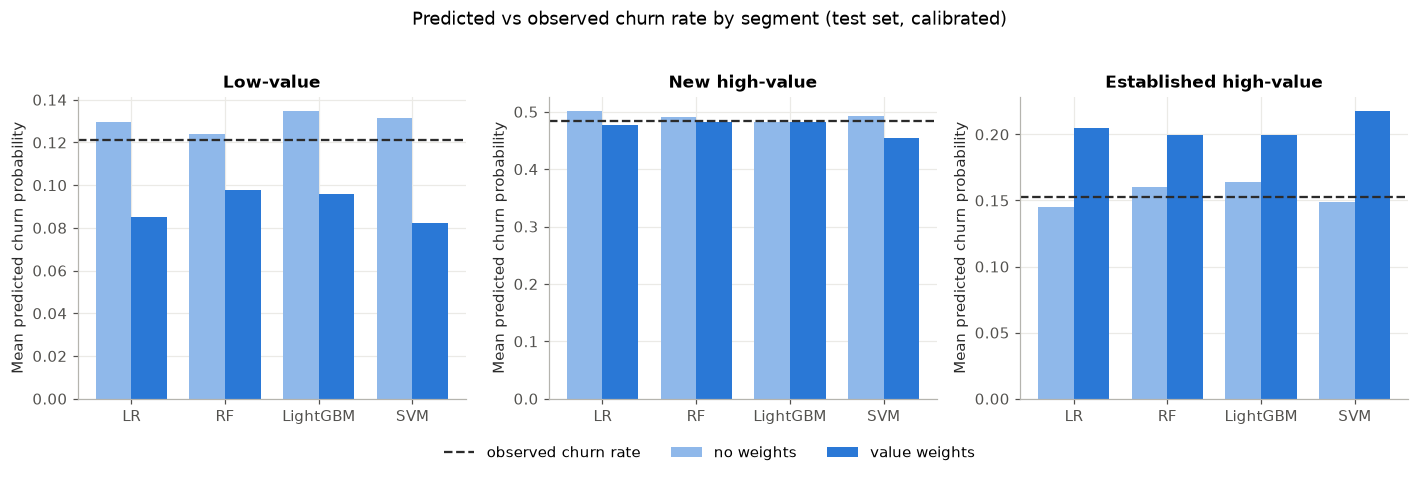

In [14]:
# Cell 14 - Figure: is the churn level of each segment right? (test set, selected calibration)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for ax, seg in zip(axes, SEGMENTS):
    obs = seg_results.xs(seg, level="segment")["Observed rate"].iloc[0]
    for j, condition in enumerate(["none", "value"]):
        vals = [seg_results.loc[(m, condition, seg), "Mean predicted"] for m in M.MODELS]
        ax.bar(np.arange(4) + (j - 0.5) * 0.38, vals, 0.38,
               color=["#8fb8ea", "#2a78d6"][j], label=["no weights", "value weights"][j])
    ax.axhline(obs, color="#2b2b2b", lw=1.5, ls="--", label="observed churn rate")
    ax.set_xticks(np.arange(4), ["LR", "RF", "LightGBM", "SVM"])
    ax.set_title(seg)
    ax.set_ylabel("Mean predicted churn probability")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=3, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Predicted vs observed churn rate by segment (test set, calibrated)", y=1.03)
fig.tight_layout()
save(fig, "12_segment_calibration_test")
plt.show()

## Step 12 – Save predictions and models for Stage 4
OOF probabilities (to choose thresholds), test probabilities (to evaluate them once) and the fitted models.

In [15]:
# Cell 15 - Save
def prediction_frame(df, y, pred):
    out = df[[C.ID_COL, "segment", "segment_k4", "MonthlyCharges"]].copy()
    out[C.TARGET] = y
    for (model_name, condition), d_ in pred.items():
        for cal in M.CALIBRATIONS:
            if d_[cal] is not None:
                out[f"{model_name}|{condition}|{cal}"] = d_[cal]
    return out

prediction_frame(train, y_train, oof).to_csv(C.PROCESSED_DIR / "stage3_oof_predictions.csv", index=False)
prediction_frame(test, y_test, test_pred).to_csv(C.PROCESSED_DIR / "stage3_test_predictions.csv", index=False)
joblib.dump({"models": final_models, "chosen_calibration": chosen.to_dict(),
             "incentive_d": D, "fold_id": fold_id}, C.MODELS_DIR / "stage3_models.joblib")
print("Saved predictions and models.")

Saved predictions and models.


## Findings
**1. Discrimination is similar across models:** test AUC 0.82–0.84; unweighted LightGBM is best (AUC 0.841, Brier 0.138). Ranking is harder in the new high-value segment (AUC 0.70–0.73) than in the low-value segment (0.85–0.88).

**2. H2 – supported for weighted and resampled models only.** Unweighted models are already calibrated (slope 0.92–1.04, ECE ≈ 0.03). With class weights, value weights or SMOTE, raw probabilities are inflated (mean 0.37–0.51 vs observed 0.27); calibration reduces the Brier score by 0.06–0.08 (significant after Holm), but the profit gains are not significant.

**3. H3 – not supported.** Value weights lower the AUC (−0.009 to −0.015) and do not raise profit (−1.04 to +0.04 per customer; all intervals include zero). They also bias segment probabilities (established high-value 0.20–0.22 predicted vs 0.15 observed).

**4. SMOTE brings no benefit** (equal or slightly worse after calibration).

**5. Economic value:** 48.3–49.9 per customer on the test set, vs 37.6 when contacting everyone and 67.0 with perfect knowledge. About half of customers are contacted.

**Carried forward to Stage 4:** the unweighted, calibrated models of all four families.